In [2]:
import pandas as pd

In [3]:
data=pd.read_csv("D:/5th sem/iris.csv")

In [4]:
print(data)

     sepal.length  sepal.width  petal.length  petal.width    variety
0             5.1          3.5           1.4          0.2     Setosa
1             4.9          3.0           1.4          0.2     Setosa
2             4.7          3.2           1.3          0.2     Setosa
3             4.6          3.1           1.5          0.2     Setosa
4             5.0          3.6           1.4          0.2     Setosa
..            ...          ...           ...          ...        ...
145           6.7          3.0           5.2          2.3  Virginica
146           6.3          2.5           5.0          1.9  Virginica
147           6.5          3.0           5.2          2.0  Virginica
148           6.2          3.4           5.4          2.3  Virginica
149           5.9          3.0           5.1          1.8  Virginica

[150 rows x 5 columns]


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [6]:
#missing values 
data.isnull().sum()

sepal.length    0
sepal.width     0
petal.length    0
petal.width     0
variety         0
dtype: int64

In [7]:
data.isnull().sum()

sepal.length    0
sepal.width     0
petal.length    0
petal.width     0
variety         0
dtype: int64

In [8]:
le=LabelEncoder()

In [9]:
data["variety"]=le.fit_transform(data["variety"])

In [10]:
data

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [11]:
#dependent and independent
x=data.drop('variety',axis=1)
y=data['variety']


In [12]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [13]:
le.classes_# classes encodes

array(['Setosa', 'Versicolor', 'Virginica'], dtype=object)

In [14]:
from sklearn.neighbors import KNeighborsClassifier

In [15]:
model_1=KNeighborsClassifier(n_neighbors=3)

In [16]:
model_1.fit(x_train,y_train)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [17]:
y_pred=model_1.predict(x_train)

In [18]:
#for train 

In [19]:
from sklearn.metrics import confusion_matrix

In [20]:
confusion_matrix(y_train,y_pred)

array([[40,  0,  0],
       [ 0, 38,  3],
       [ 0,  3, 36]])

In [21]:
from sklearn.metrics import accuracy_score

In [22]:
ac=accuracy_score(y_train,y_pred)
print(ac)

0.95


In [23]:
from sklearn.metrics import precision_score

In [24]:
p=precision_score(y_train,y_pred,average="micro")
print(p)

0.95


In [25]:
from sklearn.metrics import recall_score,f1_score

In [26]:
r=recall_score(y_train,y_pred,average="micro")
print(r)

0.95


In [27]:
f1_score(y_train, y_pred,average="micro")

0.95

In [28]:
#for test 

In [29]:
model_2=KNeighborsClassifier(n_neighbors=3)

In [30]:
model_2.fit(x_test,y_test)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [31]:
ypred_test=model_2.predict(x_test)

In [32]:
confusion_matrix(y_test,ypred_test)

array([[10,  0,  0],
       [ 0,  9,  0],
       [ 0,  1, 10]])

In [33]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

In [34]:
ac_test=accuracy_score(y_test,ypred_test)
print(ac_test)

0.9666666666666667


In [35]:
p_test=precision_score(y_test,ypred_test, average="micro")
print(p_test)

0.9666666666666667


In [36]:
recall_test=recall_score(y_test,ypred_test,average="micro")
print(recall_test)

0.9666666666666667


In [37]:
f1_score(y_test,ypred_test,average="micro")

0.9666666666666667

In [38]:
from sklearn.inspection import DecisionBoundaryDisplay

In [39]:
xnew=x_train[["sepal.length","sepal.width"]]

In [40]:
model_new=KNeighborsClassifier(n_neighbors=7)


In [41]:
model_new.fit(xnew,y_train)

,n_neighbors,7
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [42]:
ypred_new=model_new.predict(xnew)

In [43]:
import matplotlib.pyplot as plt

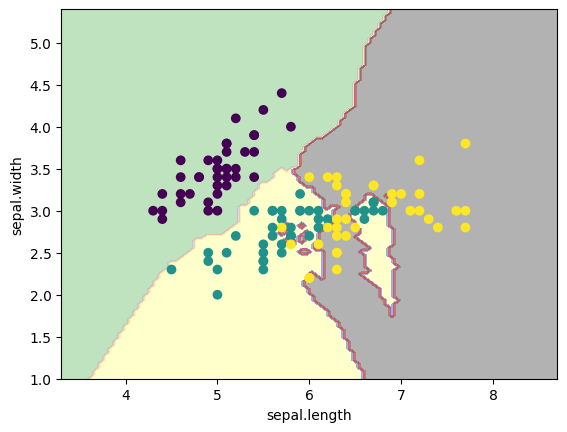

In [44]:
DecisionBoundaryDisplay.from_estimator(model_new,xnew,response_method="predict",cmap="Accent",alpha=0.5)
plt.scatter(xnew["sepal.length"],xnew["sepal.width"],c=ypred_new)

In [45]:
from sklearn.linear_model import LogisticRegression

In [46]:
model_lr = LogisticRegression(max_iter=200)
model_lr.fit(x_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'


In [47]:
ypred_train_lr = model_lr.predict(x_train)

In [48]:
confusion_matrix(y_train,ypred_train_lr)

array([[40,  0,  0],
       [ 0, 38,  3],
       [ 0,  0, 39]])

In [49]:
accuracy_score(y_train, ypred_train_lr)

0.975

In [50]:
recall_score(y_train, ypred_train_lr,average="micro")

0.975

In [51]:
f1_score(y_train, ypred_train_lr,average="micro")

0.975

In [52]:
#for test

In [53]:
ypred_test_lr = model_lr.predict(x_test)

In [54]:
accuracy_score(y_test, ypred_test_lr)

1.0

In [55]:
recall_score(y_test, ypred_test_lr,average='micro')

1.0

In [56]:
precision_score(y_test, ypred_test_lr,average="micro")

1.0

In [57]:
f1_score(y_test,ypred_test_lr,average="micro")

1.0

In [58]:
new_model_lr = LogisticRegression(max_iter=200)
new_model_lr.fit(xnew, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,200
,multi_class,'deprecated'


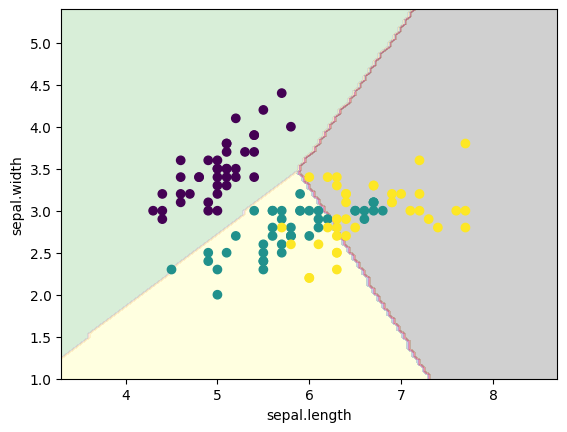

In [59]:
DecisionBoundaryDisplay.from_estimator(new_model_lr,xnew,response_method="predict",cmap="Accent",alpha=0.3)
plt.scatter(xnew["sepal.length"],xnew["sepal.width"],c=ypred_new,alpha=1)

In [60]:
sl=float(input("enter sepal length: "))
sw=float(input("enter sepal width"))
pl=float(input("enter petal length"))
pw=float(input("enter petal width"))

enter sepal length:  0.56
enter sepal width 1.03
enter petal length 0.78
enter petal width 0.96


In [61]:
x_new=pd.DataFrame([[sl,sw,pl,pw]],columns=x.columns)

In [62]:
x_new

,sepal.length,sepal.width,petal.length,petal.width
0,0.56,1.03,0.78,0.96


In [65]:
prediction = model_1.predict(x_new)
flower_name = le.inverse_transform(prediction)
print("Predicted Flower Class:", flower_name[0])


Predicted Flower Class: Setosa
